# Demosaicking con SIREN

Se modela la imagen RGB como una función de coordenadas, se ajusta a la medición Bayer y se comparan las reconstrucciones con las imágenes Kodak originales.

In [9]:
%pip install -q scikit-image pillow opencv-python pandas matplotlib

import time
import urllib.request
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from torch import nn
import torch.nn.functional as F

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BAYER_PATTERN = "GRBG"
SIREN_HIDDEN_FEATURES = 256
SIREN_HIDDEN_LAYERS = 3
SIREN_STEPS = 1000
SIREN_BATCH_SIZE = 16384
SIREN_LEARNING_RATE = 1e-4
PRINT_EVERY = 100
KODAK_URL = "https://arizona.box.com/shared/static/5bk6qar4vgfizmhum8onreu6sp90bz2i"
DATA_DIR = Path("/content/kodak") if Path("/content").exists() else Path("kodak")
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("Fig")
RESULTS_DIR = Path("resultados")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)

Device: cuda


## 1. Dataset Kodak y medición Bayer

Se separan 20 imágenes para referencia de trabajo y 4 imágenes de prueba; SIREN se ajusta individualmente a cada medición.

Imágenes Kodak: (24, 512, 768, 3)
Imágenes de prueba para SIREN: (4, 512, 768, 3)


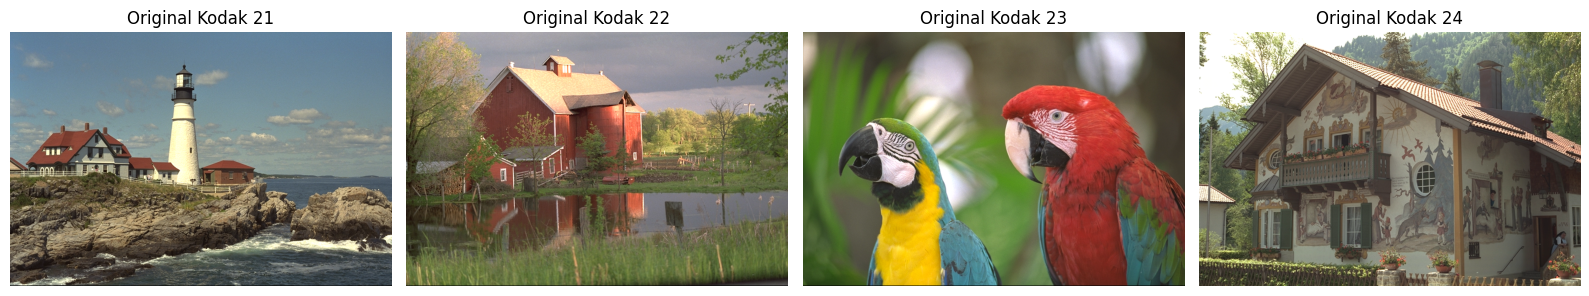

In [10]:
def download_kodak(data_dir=DATA_DIR):
    paths = sorted(data_dir.rglob("kodim*.png"))
    if len(paths) >= 24:
        return paths[:24]

    local_roots = [Path("tareas/dataset"), Path("../dataset")]
    for root in local_roots:
        local_paths = list(root.glob("*.png")) if root.exists() else []
        local_paths = sorted(local_paths, key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem)
        if len(local_paths) >= 24:
            return local_paths[:24]

    zip_path = data_dir / "kodak.zip"
    if not zip_path.exists():
        urllib.request.urlretrieve(KODAK_URL, zip_path)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(data_dir)
    paths = sorted(data_dir.rglob("kodim*.png"))
    if len(paths) < 24:
        raise RuntimeError(f"Se encontraron {len(paths)} imágenes Kodak")
    return paths[:24]

def load_rgb(path, shape=(512, 768)):
    image = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
    if image.shape[:2] != shape:
        image = torch.from_numpy(image).permute(2, 0, 1)[None]
        image = F.interpolate(image, size=shape, mode="bilinear", align_corners=False)[0].permute(1, 2, 0).numpy()
    return np.clip(image, 0.0, 1.0).astype(np.float32)

def rgb_to_bayer(image):
    image = np.asarray(image, dtype=np.float32)
    height, width = image.shape[:2]
    mosaic = np.zeros((height, width), dtype=np.float32)
    # GRBG: G R / B G
    mosaic[0::2, 0::2] = image[0::2, 0::2, 1]
    mosaic[0::2, 1::2] = image[0::2, 1::2, 0]
    mosaic[1::2, 0::2] = image[1::2, 0::2, 2]
    mosaic[1::2, 1::2] = image[1::2, 1::2, 1]
    return mosaic

def bayer_masks(height, width):
    masks = np.zeros((height, width, 3), dtype=np.float32)
    masks[0::2, 0::2, 1] = 1.0
    masks[0::2, 1::2, 0] = 1.0
    masks[1::2, 0::2, 2] = 1.0
    masks[1::2, 1::2, 1] = 1.0
    return masks

def bayer_to_rgb_opencv(mosaic):
    mosaic_u8 = np.rint(np.clip(mosaic, 0.0, 1.0) * 255).astype(np.uint8)
    return cv2.cvtColor(mosaic_u8, cv2.COLOR_BayerGR2RGB).astype(np.float32) / 255.0

kodak_paths = download_kodak()
images = np.stack([load_rgb(path) for path in kodak_paths])
train_images = images[:20]
test_images = images[20:]
print("Imágenes Kodak:", images.shape)
print("Imágenes de prueba para SIREN:", test_images.shape)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for index, (ax, image) in enumerate(zip(axes, test_images)):
    ax.imshow(image)
    ax.set_title(f"Original Kodak {index + 21}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Modelo SIREN

La red recibe coordenadas `(x,y)` y devuelve RGB; la pérdida vuelve a proyectar RGB al canal Bayer observado.

In [11]:
class SineLayer(nn.Module):
    def __init__(self, in_features, out_features, omega_0=30.0, is_first=False):
        super().__init__()
        self.omega_0 = omega_0
        self.linear = nn.Linear(in_features, out_features)
        with torch.no_grad():
            if is_first:
                self.linear.weight.uniform_(-1 / in_features, 1 / in_features)
            else:
                bound = np.sqrt(6 / in_features) / omega_0
                self.linear.weight.uniform_(-bound, bound)

    def forward(self, x):
        return torch.sin(self.omega_0 * self.linear(x))

class SirenDemosaic(nn.Module):
    def __init__(self, hidden_features=SIREN_HIDDEN_FEATURES, hidden_layers=SIREN_HIDDEN_LAYERS):
        super().__init__()
        layers = [SineLayer(2, hidden_features, is_first=True)]
        layers += [SineLayer(hidden_features, hidden_features) for _ in range(hidden_layers)]
        layers += [nn.Linear(hidden_features, 3)]
        self.net = nn.Sequential(*layers)

    def forward(self, coords):
        return torch.sigmoid(self.net(coords))

def build_coordinate_grid(height, width, device=DEVICE):
    yy, xx = torch.meshgrid(
        torch.linspace(-1, 1, height, device=device),
        torch.linspace(-1, 1, width, device=device),
        indexing="ij",
    )
    return torch.stack((xx.reshape(-1), yy.reshape(-1)), dim=-1).float()

def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

siren_example = SirenDemosaic().to(DEVICE)
print(siren_example)
print("Parámetros entrenables SIREN:", f"{parameter_count(siren_example):,}")

SirenDemosaic(
  (net): Sequential(
    (0): SineLayer(
      (linear): Linear(in_features=2, out_features=256, bias=True)
    )
    (1): SineLayer(
      (linear): Linear(in_features=256, out_features=256, bias=True)
    )
    (2): SineLayer(
      (linear): Linear(in_features=256, out_features=256, bias=True)
    )
    (3): SineLayer(
      (linear): Linear(in_features=256, out_features=256, bias=True)
    )
    (4): Linear(in_features=256, out_features=3, bias=True)
  )
)
Parámetros entrenables SIREN: 198,915


## 3. Entrenamiento físico para una imagen

Se ajusta una SIREN por imagen usando únicamente la medición Bayer, sin usar la imagen RGB original como objetivo.

Paso 0001/1000 | pérdida Bayer: 0.05881717
Paso 0100/1000 | pérdida Bayer: 0.00714427
Paso 0200/1000 | pérdida Bayer: 0.00613749
Paso 0300/1000 | pérdida Bayer: 0.00541266
Paso 0400/1000 | pérdida Bayer: 0.00526937
Paso 0500/1000 | pérdida Bayer: 0.00473280
Paso 0600/1000 | pérdida Bayer: 0.00452468
Paso 0700/1000 | pérdida Bayer: 0.00422980
Paso 0800/1000 | pérdida Bayer: 0.00398509
Paso 0900/1000 | pérdida Bayer: 0.00375570
Paso 1000/1000 | pérdida Bayer: 0.00373937
Tiempo de entrenamiento: 9.6 s


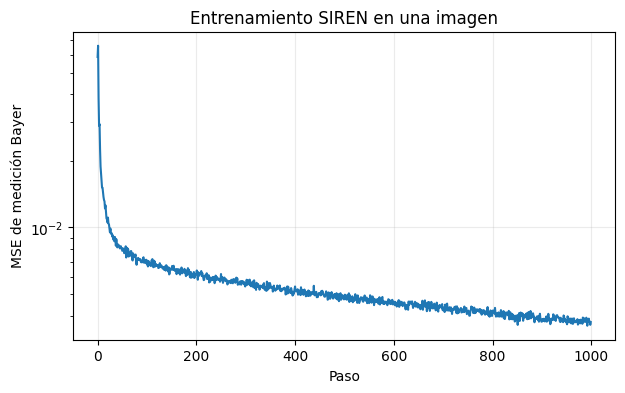

In [12]:
def train_siren(image, steps=SIREN_STEPS, batch_size=SIREN_BATCH_SIZE, learning_rate=SIREN_LEARNING_RATE, print_every=PRINT_EVERY):
    height, width = image.shape[:2]
    mosaic = rgb_to_bayer(image)
    masks = bayer_masks(height, width)
    coords = build_coordinate_grid(height, width)
    observed = torch.from_numpy(mosaic.reshape(-1)).to(DEVICE)
    mask_tensor = torch.from_numpy(masks.reshape(-1, 3)).to(DEVICE)

    model = SirenDemosaic().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    start = time.perf_counter()

    model.train()
    for step in range(1, steps + 1):
        indices = torch.randint(0, coords.shape[0], (batch_size,), generator=generator, device=DEVICE)
        prediction = model(coords[indices])
        predicted_mosaic = torch.sum(prediction * mask_tensor[indices], dim=-1)
        loss = F.mse_loss(predicted_mosaic, observed[indices])
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach().cpu()))
        if step == 1 or step % print_every == 0 or step == steps:
            print(f"Paso {step:04d}/{steps} | pérdida Bayer: {history[-1]:.8f}")

    print(f"Tiempo de entrenamiento: {time.perf_counter() - start:.1f} s")
    return model, history, mosaic

def predict_siren(model, height, width, batch_size=65536):
    model.eval()
    coords = build_coordinate_grid(height, width)
    chunks = []
    with torch.no_grad():
        for chunk in coords.split(batch_size):
            chunks.append(model(chunk).cpu())
    return torch.cat(chunks).reshape(height, width, 3).numpy().astype(np.float32)

particular_index = 2
particular_image = test_images[particular_index]
siren_particular, particular_history, particular_mosaic = train_siren(particular_image)
particular_prediction = predict_siren(siren_particular, *particular_image.shape[:2])

plt.figure(figsize=(7, 4))
plt.plot(particular_history)
plt.yscale("log")
plt.xlabel("Paso")
plt.ylabel("MSE de medición Bayer")
plt.title("Entrenamiento SIREN en una imagen")
plt.grid(alpha=0.25)
plt.show()

## 4. Comparación de una imagen y zoom

Se compara la imagen original con bilineal/OpenCV y SIREN en la vista completa y en una zona ampliada.

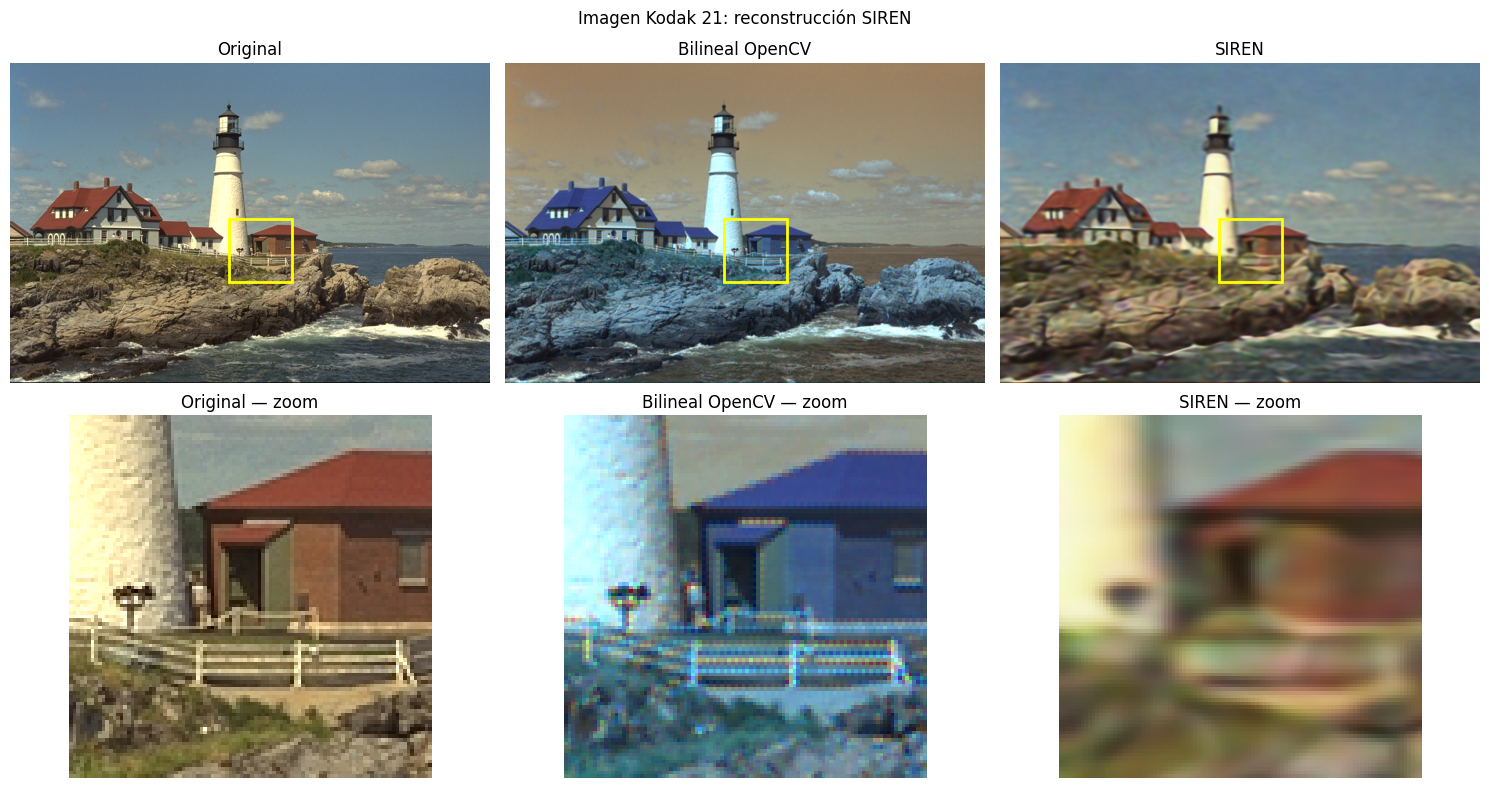

In [13]:
def crop_box(image, box):
    x0, y0, x1, y1 = box
    height, width = image.shape[:2]
    return image[max(0, y0):min(height, y1), max(0, x0):min(width, x1)]

def compare_with_zoom(reference, reconstructions, box=(60, 165, 300, 365), title="Comparación SIREN", save_path=None):
    names = [("Original", reference)] + list(reconstructions.items())
    x0, y0, x1, y1 = box
    fig, axes = plt.subplots(2, len(names), figsize=(5 * len(names), 8))
    if len(names) == 1: axes = axes[:, None]
    for col, (name, image) in enumerate(names):
        axes[0, col].imshow(image)
        axes[0, col].set_title(name)
        axes[0, col].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="yellow", linewidth=2))
        axes[1, col].imshow(crop_box(image, box))
        axes[1, col].set_title(f"{name} — zoom")
        axes[0, col].axis("off")
        axes[1, col].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()

particular_bilinear = bayer_to_rgb_opencv(particular_mosaic)
compare_with_zoom(
    particular_image,
    {"Bilineal OpenCV": particular_bilinear, "SIREN": particular_prediction},
    title=f"Imagen Kodak {particular_index + 21}: reconstrucción SIREN",
    save_path=FIG_DIR / "siren_kodak23_zoom.png",
)

## 5. SIREN sobre todas las imágenes de prueba

Se entrena una representación independiente para cada imagen y se comparan sus métricas con la referencia RGB.

In [14]:
def compute_metrics(reference, estimate):
    reference = np.clip(reference.astype(np.float32), 0.0, 1.0)
    estimate = np.clip(estimate.astype(np.float32), 0.0, 1.0)
    mse = float(np.mean((reference - estimate) ** 2))
    psnr = float(peak_signal_noise_ratio(reference, estimate, data_range=1.0))
    ssim = float(structural_similarity(reference, estimate, channel_axis=-1, data_range=1.0))
    return {"MSE": mse, "PSNR [dB]": psnr, "SSIM": ssim}

particular_name = f"SIREN imagen {particular_index + 21}"
siren_models = {particular_name: siren_particular}
siren_histories = {particular_name: particular_history}
siren_predictions = {particular_name: particular_prediction}

for index, image in enumerate(test_images):
    if index == particular_index:
        continue
    image_number = index + 21
    model, history, mosaic = train_siren(image)
    prediction = predict_siren(model, *image.shape[:2])
    siren_models[f"SIREN imagen {image_number}"] = model
    siren_histories[f"SIREN imagen {image_number}"] = history
    siren_predictions[f"SIREN imagen {image_number}"] = prediction

rows = []
per_image_predictions = {}
for index, image in enumerate(test_images):
    name = f"SIREN imagen {index + 21}"
    siren_prediction = siren_predictions[name]
    bilinear_prediction = bayer_to_rgb_opencv(rgb_to_bayer(image))
    per_image_predictions[name] = siren_prediction
    rows.append({"method": "Bilineal OpenCV", "imagen": index + 21, **compute_metrics(image, bilinear_prediction)})
    rows.append({"method": name, "imagen": index + 21, **compute_metrics(image, siren_prediction)})

metrics_df = pd.DataFrame(rows)
display(metrics_df.round(4))
metrics_df.to_csv(RESULTS_DIR / "siren_metrics.csv", index=False)
print("Tabla guardada en:", RESULTS_DIR / "siren_metrics.csv")
display(metrics_df.groupby("method")[["MSE", "PSNR [dB]", "SSIM"]].mean().round(4))

Paso 0001/1000 | pérdida Bayer: 0.05161770
Paso 0100/1000 | pérdida Bayer: 0.00444603
Paso 0200/1000 | pérdida Bayer: 0.00390368
Paso 0300/1000 | pérdida Bayer: 0.00384932
Paso 0400/1000 | pérdida Bayer: 0.00339305
Paso 0500/1000 | pérdida Bayer: 0.00350865
Paso 0600/1000 | pérdida Bayer: 0.00304562
Paso 0700/1000 | pérdida Bayer: 0.00313432
Paso 0800/1000 | pérdida Bayer: 0.00286892
Paso 0900/1000 | pérdida Bayer: 0.00282301
Paso 1000/1000 | pérdida Bayer: 0.00256671
Tiempo de entrenamiento: 10.0 s
Paso 0001/1000 | pérdida Bayer: 0.06368606
Paso 0100/1000 | pérdida Bayer: 0.00262668
Paso 0200/1000 | pérdida Bayer: 0.00223938
Paso 0300/1000 | pérdida Bayer: 0.00177309
Paso 0400/1000 | pérdida Bayer: 0.00162859
Paso 0500/1000 | pérdida Bayer: 0.00162735
Paso 0600/1000 | pérdida Bayer: 0.00151130
Paso 0700/1000 | pérdida Bayer: 0.00127291
Paso 0800/1000 | pérdida Bayer: 0.00136865
Paso 0900/1000 | pérdida Bayer: 0.00118499
Paso 1000/1000 | pérdida Bayer: 0.00108524
Tiempo de entrenamient

,method,imagen,MSE,PSNR [dB],SSIM
0,Bilineal OpenCV,21,0.0158,18.0256,0.8176
1,SIREN imagen 21,21,0.0038,24.1788,0.6963
2,Bilineal OpenCV,22,0.0207,16.8494,0.7793
3,SIREN imagen 22,22,0.0028,25.4815,0.6067
4,Bilineal OpenCV,23,0.0586,12.3206,0.7781
5,SIREN imagen 23,23,0.0013,28.7843,0.8579
6,Bilineal OpenCV,24,0.0092,20.3515,0.8245
7,SIREN imagen 24,24,0.0053,22.7273,0.6027


,MSE,PSNR [dB],SSIM
method,,,
Bilineal OpenCV,0.0261,16.8867,0.7999
SIREN imagen 21,0.0038,24.1788,0.6963
SIREN imagen 22,0.0028,25.4815,0.6067
SIREN imagen 23,0.0013,28.7843,0.8579
SIREN imagen 24,0.0053,22.7273,0.6027


## 6. Galería completa y mejor reconstrucción

Se visualizan todas las imágenes originales junto con sus reconstrucciones SIREN y se revisa el mejor resultado.

Mejor SIREN por PSNR: SIREN imagen 23


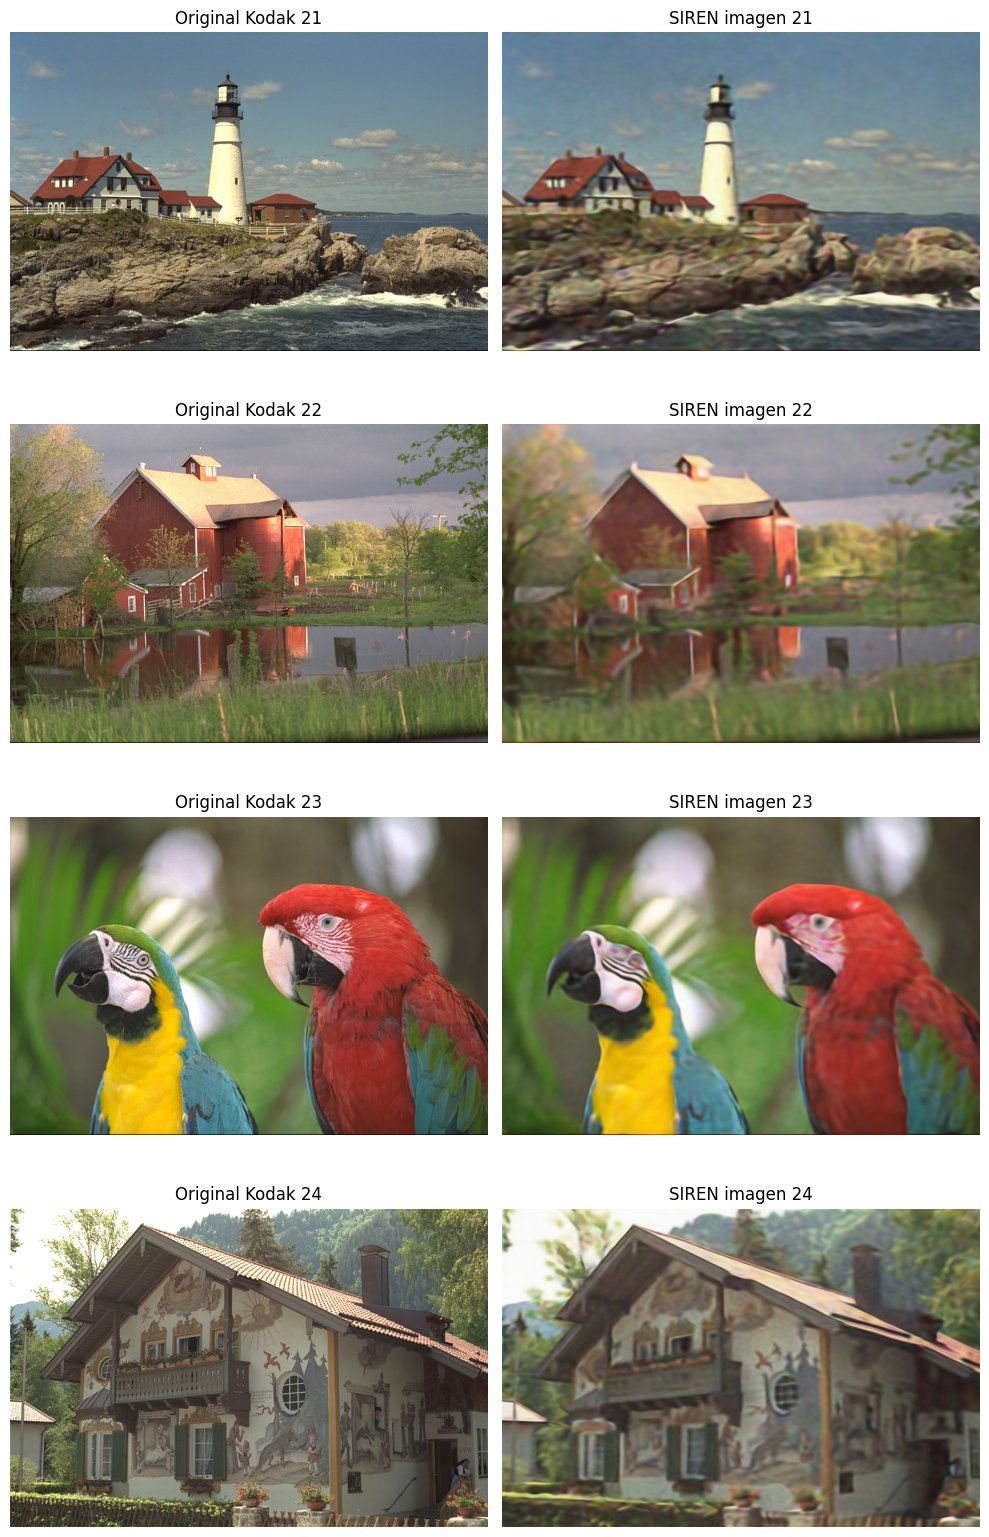

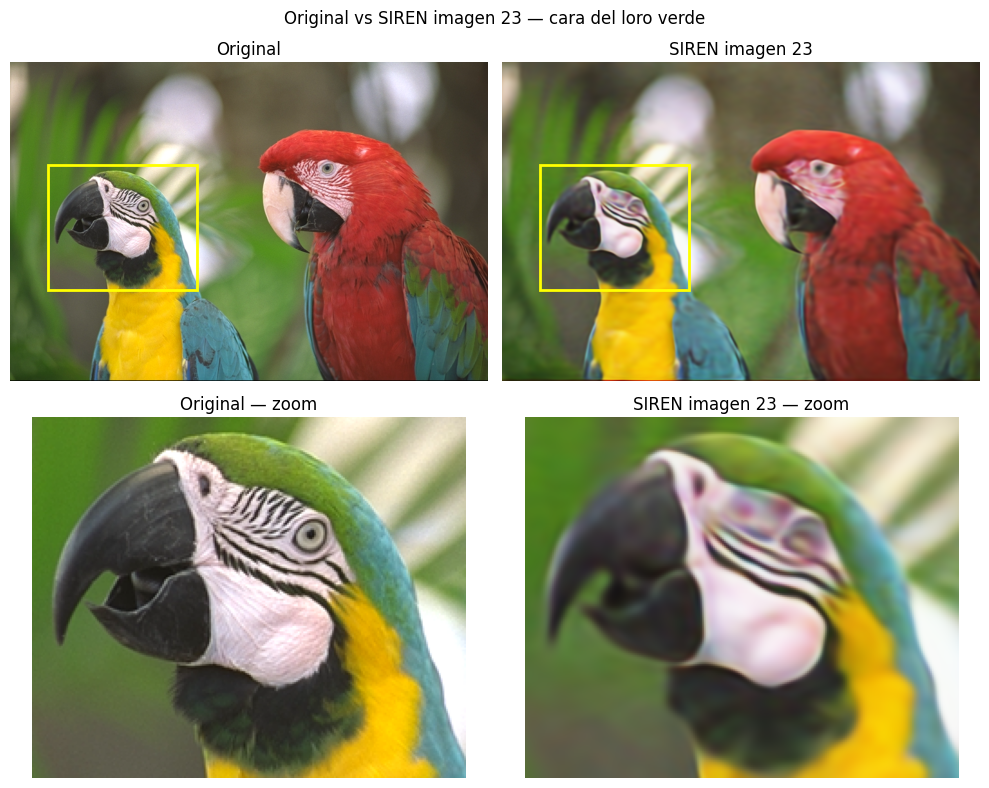

In [15]:
siren_mean_metrics = metrics_df[metrics_df["method"].str.startswith("SIREN")].groupby("method")["PSNR [dB]"].mean()
best_siren_name = siren_mean_metrics.idxmax()
best_siren_prediction = siren_predictions[best_siren_name]
best_siren_index = int(best_siren_name.split()[-1]) - 21
print("Mejor SIREN por PSNR:", best_siren_name)

fig, axes = plt.subplots(len(test_images), 2, figsize=(10, 4 * len(test_images)))
if len(test_images) == 1: axes = axes[None, :]
for row, image in enumerate(test_images):
    name = f"SIREN imagen {row + 21}"
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original Kodak {row + 21}")
    axes[row, 1].imshow(siren_predictions[name])
    axes[row, 1].set_title(name)
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "siren_todas_las_imagenes.png", dpi=180, bbox_inches="tight")
plt.show()

compare_with_zoom(
    test_images[best_siren_index],
    {best_siren_name: best_siren_prediction},
    box=(60, 165, 300, 365),
    title=f"Original vs {best_siren_name} — cara del loro verde",
    save_path=FIG_DIR / "siren_mejor_zoom.png",
)